<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization: Stacked Charts**
**IBM Skills Network guided lab | Portfolio edition**

### Project Overview
Stacked charts help show how different categories contribute to an overall total. In this lab, I use developer survey responses to compare job-satisfaction measures, compensation, database interests, programming languages, and technology preferences across demographic and employment groups.

**Guiding question:** Which patterns stand out across developer groups, and how much of each pattern reflects differences in group size or measurement?

**Approach:** Load the survey data, group and summarize responses, create eight stacked charts, and interpret each visualization with attention to its limitations.

**Tools and skills:** Python, Pandas, Matplotlib, data aggregation, multi-select response preparation, and data storytelling.

*This notebook follows the original IBM Skills Network guided lab. The additional explanations and chart interpretations are portfolio documentation.*

Estimated time needed: **45** minutes


### Objectives


In this lab, you will perform the following:
- Visualize the composition of data using stacked charts.
- Compare multiple variables across different categories using stacked charts.
- Analyze trends within stacked chart visualizations.

### Setup: Downloading and Loading the Data
**Install the libraries**


In [1]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/10.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 183.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.7 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 190.7 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
!pip install matplotlib
!pip install seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/9.9 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 128.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/5.4 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 113.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 64.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/6.9 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 140.5 MB/s eta 0:00:00

   ━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [pillow]
   ━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [pillow]
   ━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/7 [kiwisolver]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━

**Download and Load the Data**


To start, download and load the dataset into a `pandas` DataFrame.



#### Step 1: Download the dataset


In [3]:
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

--2026-10-15 09:14:47--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 
200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv       0%[                    ]       0  --.-KB/s               
survey-data.csv       0%[                    ] 519.03K  1.61MB/s               
survey-data.csv       3%[                    ]   5.88M  6.79MB/s               
survey-data.csv       6%[>                   ]   9.99M  7.31MB/s               
survey-data.csv      11%[=>                  ]  17.68M  11.3MB/s               
survey-data.csv      12%[=>            

#### Step 2: Import necessary libraries and load the dataset


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Load the data


In [7]:
df = pd.read_csv("survey-data.csv")

#### Display the first few rows of the data to understand its structure


In [10]:
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Stacked Chart for Composition of Job Satisfaction Across Age Groups


##### 1. Stacked Chart of Median `JobSatPoints_6` and `JobSatPoints_7` for Different Age Groups


Visualize the composition of job satisfaction scores (`JobSatPoints_6` and `JobSatPoints_7`) across various age groups. This will help in understanding the breakdown of satisfaction levels across different demographics.



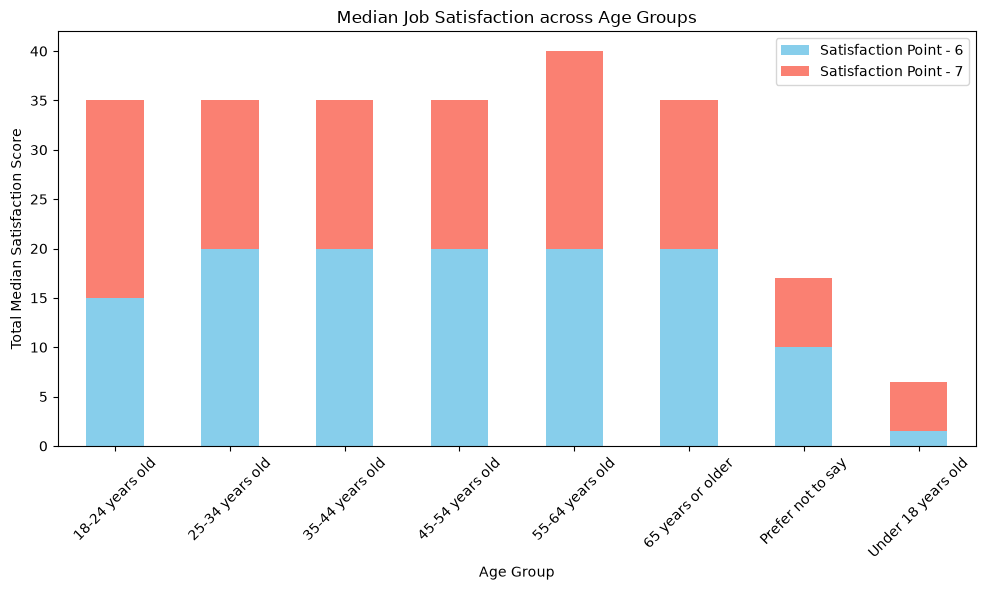

In [11]:
##Write your code here
df_grouped = df.groupby('Age')[['JobSatPoints_6', 'JobSatPoints_7']].median()

df_grouped.plot(kind='bar', stacked=True, figsize=(10, 6), color=['skyblue', 'salmon'])
plt.title('Median Job Satisfaction across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Total Median Satisfaction Score')
plt.xticks(rotation=45)
plt.legend(['Satisfaction Point - 6', 'Satisfaction Point - 7'])
plt.tight_layout()
plt.show()

Most adult age groups have similarly sized stacked bars, around 35 in total, while the 55-64 group reaches approximately 40. The 18-24 group has a smaller contribution from JobSatPoints_6 than the 25-64 groups. The under-18 and "prefer not to say" categories are much lower.

**What this means:** The chart reveals differences in the two reported satisfaction-point measures across age categories, but it does not establish that one age group is more satisfied overall. Each segment is a separate median; adding medians creates a combined display value rather than a meaningful total satisfaction score. 

##### Stacked Chart of `JobSatPoints_6` and `JobSatPoints_7` for Employment Status


Create a stacked chart to compare job satisfaction (`JobSatPoints_6` and `JobSatPoints_7`) across different employment statuses. This will show how satisfaction varies by employment type.


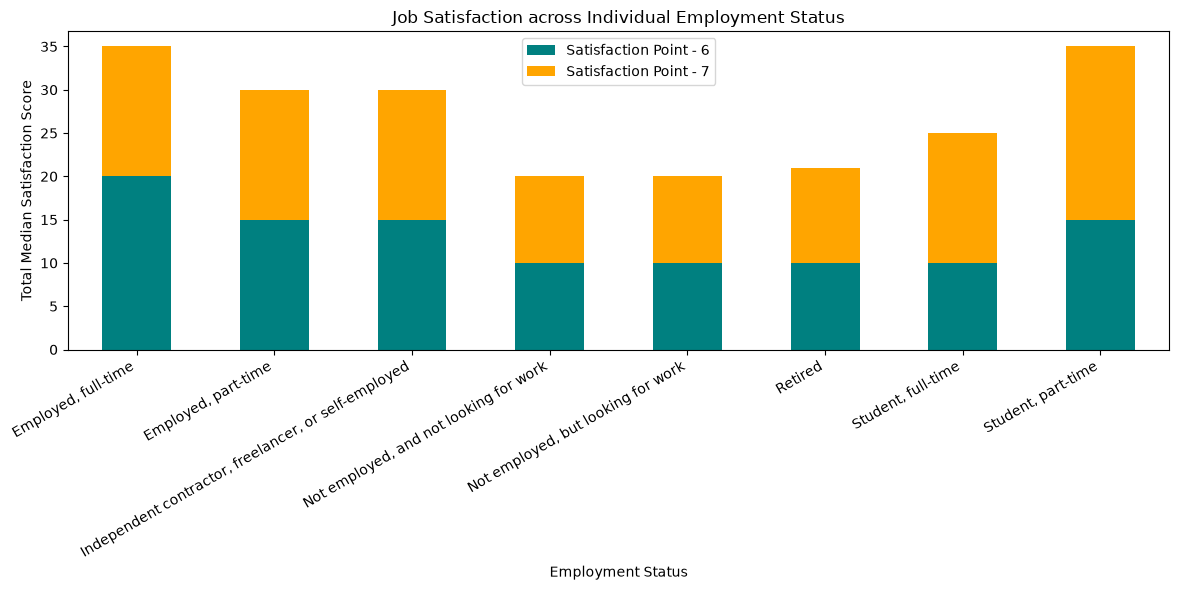

In [15]:
##Write your code here
df_emp_sat = df[['Employment', 'JobSatPoints_6', 'JobSatPoints_7']].dropna().copy()
df_emp_exploded = df_emp_sat.assign(Employment=df_emp_sat['Employment'].str.split(';')).explode('Employment')
df_emp_grouped = df_emp_exploded.groupby('Employment')[['JobSatPoints_6', 'JobSatPoints_7']].median()

df_emp_grouped.plot(kind='bar', stacked=True, figsize=(12, 6), color=['teal', 'orange'])
plt.title('Job Satisfaction across Individual Employment Status')
plt.xlabel('Employment Status')
plt.ylabel('Total Median Satisfaction Score')
plt.xticks(rotation=30, ha='right')
plt.legend(['Satisfaction Point - 6', 'Satisfaction Point - 7'])
plt.tight_layout()
plt.show()

The stacked values are highest for full-time employees and part-time students, at roughly 35, followed by part-time employees and independent contractors at about 30. Several not-working categories sit around 20.

**What this means:** The two survey measures differ across employment groups, but these totals are not overall satisfaction scores. Each segment represents a separately calculated median, and the stacked height is their sum. Respondents with multiple employment statuses can appear in more than one group, while the chart does not show sample sizes.

### Task 2: Stacked Chart for Compensation and Job Satisfaction by Age Group


##### This stacked chart visualizes the composition of compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`) specifically for respondents aged 30-35.


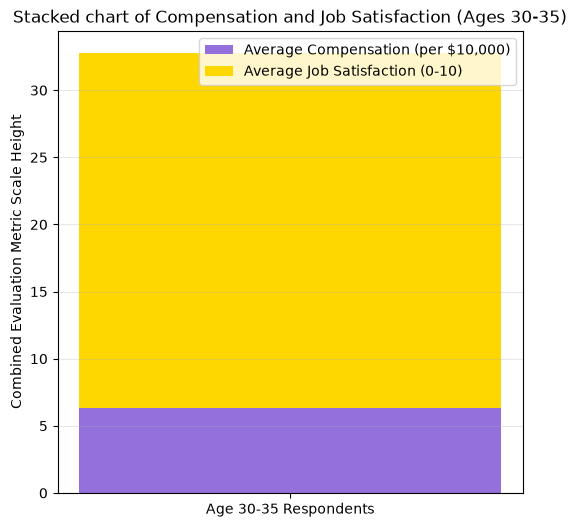

In [18]:
##Write your code here
df_age= df[df['Age'] == '25-34 years old'].dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6']).copy()

Q1 = df_age['ConvertedCompYearly'].quantile(0.25)
Q3 = df_age['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_age_clean = df_age[df_age['ConvertedCompYearly'] <= (Q3 + 1.5 * IQR)]

avg_comp = df_age_clean['ConvertedCompYearly'].mean()
avg_sat = df_age_clean['JobSatPoints_6'].mean()
scaled_comp = avg_comp / 10000

plt.figure(figsize=(6, 6))
plt.bar(['Age 30-35 Respondents'], [scaled_comp], color='mediumpurple', label='Average Compensation (per $10,000)', width=0.4)
plt.bar(['Age 30-35 Respondents'], [avg_sat], bottom=[scaled_comp], color='gold', label='Average Job Satisfaction (0-10)', width=0.4)
plt.title('Stacked chart of Compensation and Job Satisfaction (Ages 30-35)')
plt.ylabel('Combined Evaluation Metric Scale Height')
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.show()

The saved chart has a compensation segment of roughly 6 units (compensation divided by 10,000) and a much larger satisfaction segment, producing a stacked height of about 33. The satisfaction segment therefore dominates the visual total.

**What this means:** The stacked height has no single interpretable unit because it combines a monetary measure, scaled by 10,000, with a satisfaction measure. It should not be read as a combined measure of financial and personal well-being.

##### Stacked Chart of Median Compensation and Job Satisfaction Across Age Group


Compare the median compensation and job satisfaction metrics across different age groups. This helps visualize how compensation and satisfaction levels differ by age.


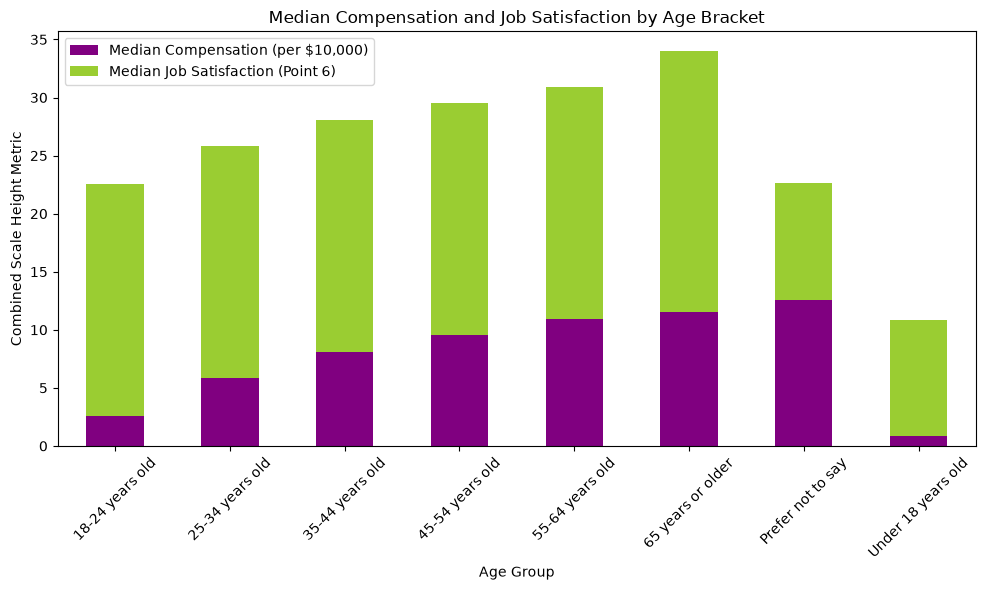

In [20]:
##Write your code here
df_clean = df.dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6']).copy()

Q1 = df_clean['ConvertedCompYearly'].quantile(0.25)
Q3 = df_clean['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_no_outliers = df_clean[df_clean['ConvertedCompYearly'] <= (Q3 + 1.5 * IQR)]

df_medians = df_no_outliers.groupby('Age')[['ConvertedCompYearly', 'JobSatPoints_6']].median()
df_medians['ConvertedCompYearly_Scaled'] = df_medians['ConvertedCompYearly'] / 10000

df_medians[['ConvertedCompYearly_Scaled', 'JobSatPoints_6']].plot(kind='bar', stacked=True, figsize=(10, 6), color=['purple', 'yellowgreen'])
plt.title('Median Compensation and Job Satisfaction by Age Bracket')
plt.xlabel('Age Group')
plt.ylabel('Combined Scale Height Metric')
plt.xticks(rotation=45)
plt.legend(['Median Compensation (per $10,000)', 'Median Job Satisfaction (Point 6)'])
plt.tight_layout()
plt.show()

The purple compensation component generally rises from younger adult groups toward older age categories, while the green satisfaction component accounts for much of each stacked bar. The combined bar for respondents aged 65 or older is among the tallest; the under-18 group is much shorter.

**What this means:** The compensation component suggests differences in median reported pay by age group after the lab's upper-outlier filter.

### Task 3: Comparing Data Using Stacked Charts


##### 1. Stacked Chart of Preferred Databases by Age Group




Visualize the top databases that respondents from different age groups wish to learn. Create a stacked chart to show the proportion of each database in each age group.


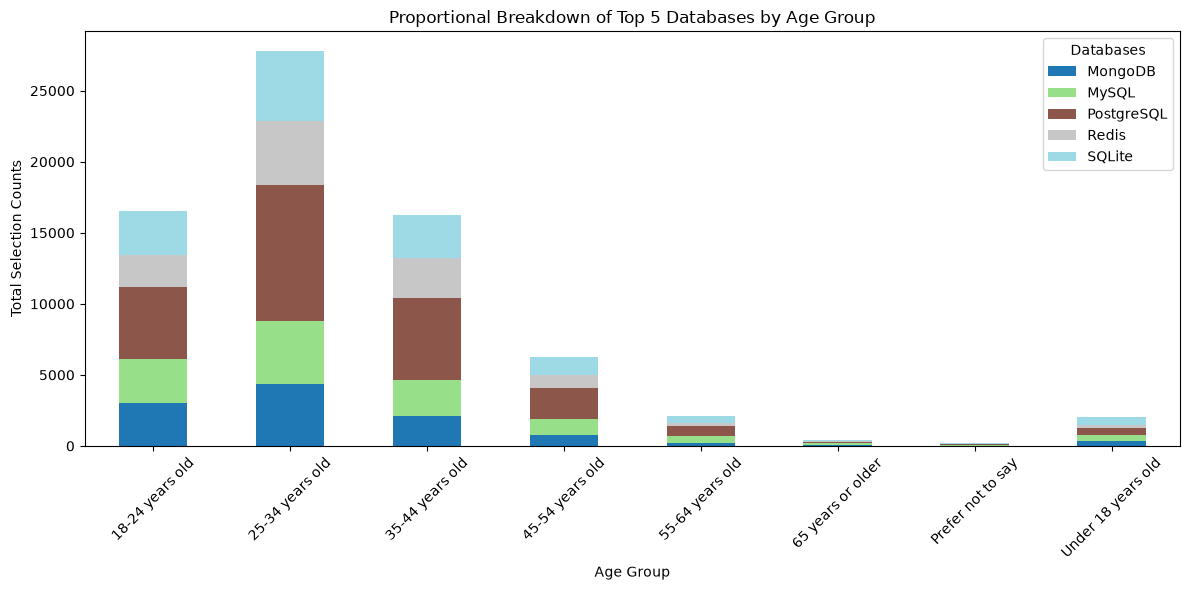

In [25]:
##Write your code here
df_db = df[['Age', 'DatabaseWantToWorkWith']].dropna()
df_exploded = df_db.assign(Database=df_db['DatabaseWantToWorkWith'].str.split(';')).explode('Database')

top_5_dbs = df_exploded['Database'].value_counts().head(5).index
df_filtered = df_exploded[df_exploded['Database'].isin(top_5_dbs)]
df_pivot = df_filtered.groupby(['Age', 'Database']).size().unstack(fill_value=0)

df_pivot.plot(kind='bar', stacked=True, figsize=(12, 6), cmap='tab20')
plt.title('Proportional Breakdown of Top 5 Databases by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Selection Counts')
plt.xticks(rotation=45)
plt.legend(title='Databases')
plt.tight_layout()
plt.show()

The 25-34 age group has the largest total number of selections among the five displayed databases. The 18-24 and 35-44 groups are also prominent, while older groups and the under-18 category have far fewer mentions. PostgreSQL, MySQL, MongoDB, Redis, and SQLite make up the stacked segments.

**What this means:** These are counts of database mentions, not the proportion of respondents in each age group who want to learn a database. The 25-34 group's large total may partly reflect greater survey participation.

##### 2. Stacked Chart of Employment Type by Job Satisfaction


Analyze the distribution of employment types within each job satisfaction level using a stacked chart. This will provide insights into how employment types are distributed across various satisfaction ratings.


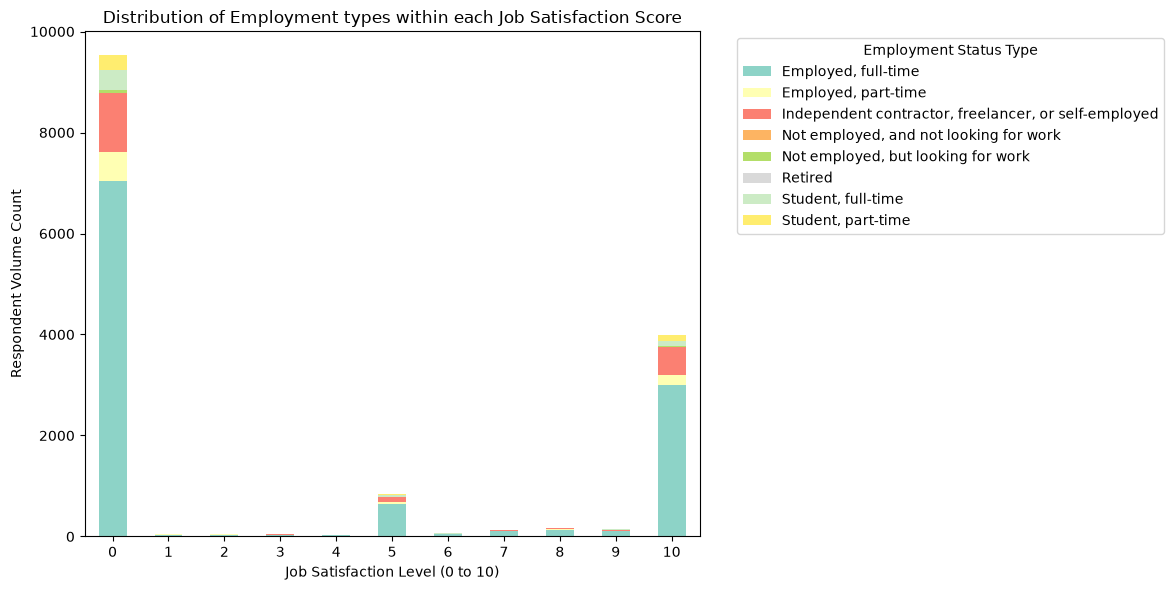

In [32]:
##Write your code here
df_emp_sat = df[['JobSatPoints_6', 'Employment']].dropna().copy()
df_emp_sat['JobSatPoints_6'] = df_emp_sat['JobSatPoints_6'].astype(int)
df_exploded = df_emp_sat.assign(Employment=df_emp_sat['Employment'].str.split(';')).explode('Employment')
df_pivot = df_exploded.groupby(['JobSatPoints_6', 'Employment']).size().unstack(fill_value=0)
df_pivot = df_pivot.reindex(range(11), fill_value=0)

df_pivot.plot(kind='bar', stacked=True, figsize=(12, 6), cmap='Set3')

plt.title('Distribution of Employment types within each Job Satisfaction Score')
plt.xlabel('Job Satisfaction Level (0 to 10)')
plt.ylabel('Respondent Volume Count')
plt.xticks(ticks=range(11), labels=range(11), rotation=0) 
plt.legend(title='Employment Status Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

The chart is highly concentrated at satisfaction values 0 and 10, with much smaller counts at most intermediate values. The largest segments within those two bars come from full-time employment. A smaller peak appears around the value 5.

**What this means:** The distribution is unusually concentrated at the endpoints, so it would be premature to describe it as a normal pattern of satisfaction.

### Task 4: Exploring Technology Preferences Using Stacked Charts


##### 1. Stacked Chart for Preferred Programming Languages by Age Group


Analyze how programming language preferences (`LanguageAdmired`) vary across age groups.


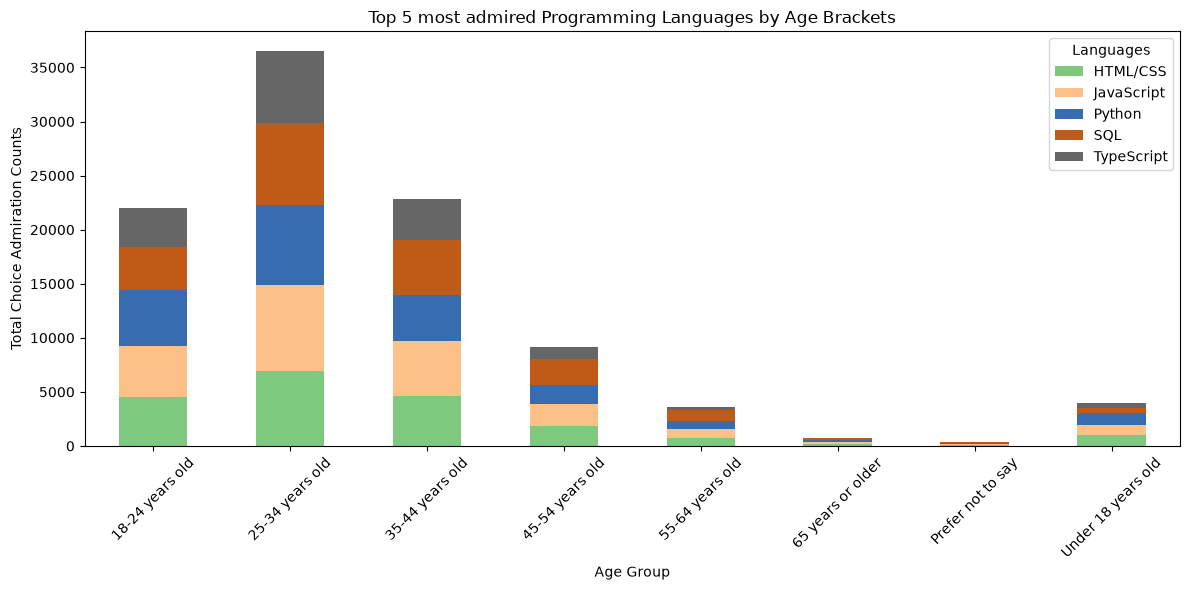

In [36]:
##Write your code here
df_lang = df[['Age', 'LanguageAdmired']].dropna()
df_exploded = df_lang.assign(Language=df_lang['LanguageAdmired'].str.split(';')).explode('Language')

top_5_lang = df_exploded['Language'].value_counts().head(5).index
df_filtered = df_exploded[df_exploded['Language'].isin(top_5_lang)]
df_pivot = df_filtered.groupby(['Age', 'Language']).size().unstack(fill_value=0)

df_pivot.plot(kind='bar', stacked=True, figsize=(12, 6), cmap='Accent')
plt.title('Top 5 most admired Programming Languages by Age Brackets')
plt.xlabel('Age Group')
plt.ylabel('Total Choice Admiration Counts')
plt.xticks(rotation=45)
plt.legend(title='Languages')
plt.tight_layout()
plt.show()

The 25-34 age group has the highest total number of mentions across the five displayed languages. The 18-24 and 35-44 groups also account for substantial selections. Python, JavaScript, SQL, HTML/CSS, and TypeScript appear across several age groups, indicating that admiration for these languages is not limited to a single age bracket.

**What this means:** The stacked totals represent language mentions, not the number of unique developers or the percentage of a group that admires each language.

##### 2. Stacked Chart for Technology Adoption by Employment Type


Explore how admired platforms (`PlatformAdmired`) differ across employment types (e.g., full-time, freelance)


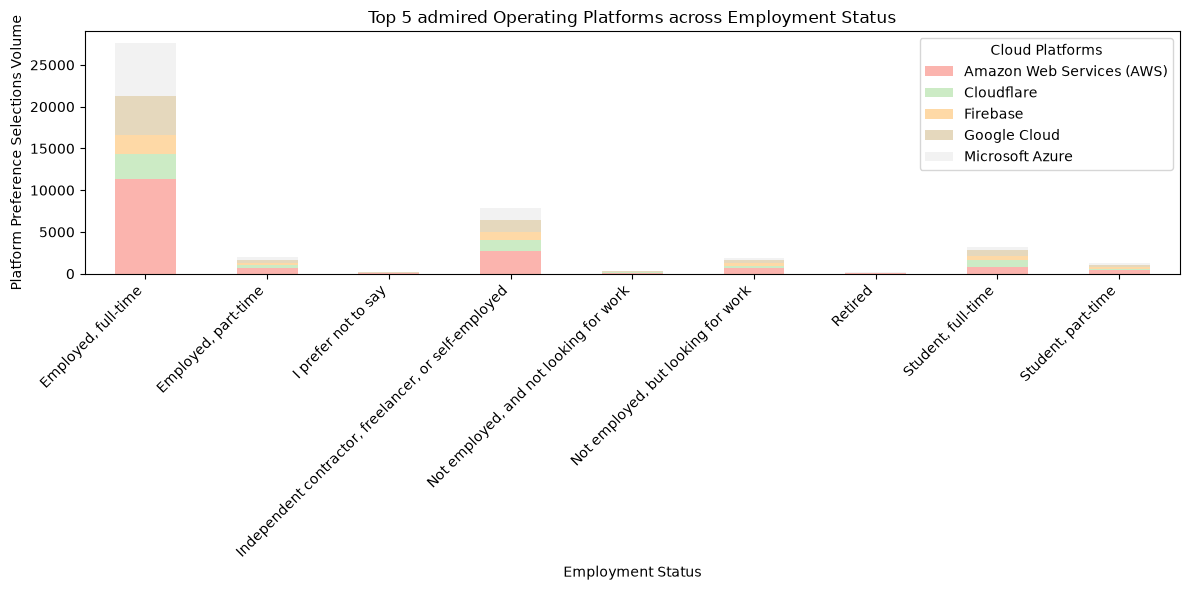

In [40]:
##Write your code here
df_platform = df[['Employment', 'PlatformAdmired']].dropna()
df_exploded = df_platform.assign(Employment=df_platform['Employment'].str.split(';'),
                                 Platform=df_platform['PlatformAdmired'].str.split(';')).explode('Employment').explode('Platform')

top_5_platform = df_exploded['Platform'].value_counts().head(5).index
df_filtered = df_exploded[df_exploded['Platform'].isin(top_5_platform)]
df_pivot = df_filtered.groupby(['Employment', 'Platform']).size().unstack(fill_value=0)

df_pivot.plot(kind='bar', stacked=True, figsize=(12, 6), cmap='Pastel1')
plt.title('Top 5 admired Operating Platforms across Employment Status')
plt.xlabel('Employment Status')
plt.ylabel('Platform Preference Selections Volume')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Cloud Platforms')
plt.tight_layout()
plt.show()

Full-time employees account for by far the largest number of platform mentions. Independent contractors and self-employed respondents form a smaller but visible group, followed by part-time students and other employment categories. Amazon Web Services (AWS), Microsoft Azure, Google Cloud, Cloudflare, and Firebase make up the displayed top-five platform selections.

**What this means:** The dominance of full-time employment is primarily a statement about the volume of survey mentions, not proof that full-time employees prefer cloud platforms more strongly. Employment categories can overlap, and each respondent may select several platforms.

### Key Findings
- Age groups differ in the volume of technology selections. The 25-34 group accounts for the most mentions in the database and programming-language charts, but raw counts are influenced by survey participation.
- Full-time employment dominates several count-based comparisons. This reflects the number of recorded selections and does not, by itself, establish stronger preferences.
- Some satisfaction-based charts require verification. The plotted values and the assumed 0-10 scale are not consistent across the lab.
- Stacking unrelated measures can be misleading. Combining compensation and satisfaction in one stacked bar produces a total without a meaningful shared unit.
- Multiple selections matter. Respondents can report more than one language, database, platform, or employment status, so counts may overlap.

### Limitations and Next Steps
These visualizations describe survey responses rather than the entire developer workforce. Group sizes differ, some categories overlap, and the code filters missing values and high compensation figures in selected analyses. To strengthen the results, I would validate the satisfaction-field definitions, correct the 25-34 versus 30-35 age label, use percentages for comparisons across differently sized groups, and separate measures with incompatible units.

### Skills Demonstrated
- Data preparation: Filtering survey records, splitting multi-select responses, and handling missing values.
- Analysis: Calculating medians, means, grouped counts, and interquartile-range thresholds.
- Visualization: Creating stacked bar charts and identifying when this chart type is appropriate.
- Interpretation: Explaining patterns, sample-size effects, and measurement limitations without overstating conclusions.

### Summary


After completing this lab, you will be able to:
- Use stacked charts to analyze the composition of data across categories, such as job satisfaction and compensation by age group.
- Compare data across different dimensions using stacked charts, enhancing your ability to communicate complex relationships in the data.
- Visualize distributions across multiple categories, such as employment type by satisfaction, to gain a deeper understanding of patterns within the dataset.

*Attribution: Original lab material, branding, and copyright belong to IBM Skills Network. Portfolio explanations and chart interpretations have been added.*

### Author:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
